# Benchmark visual para estimação de canal OFDM

Este notebook foi feito para o código modularizado baseado em `construct.py` e módulos auxiliares (`ofdm_config.py`, `ofdm_blocks.py`, `ofdm_estimators.py`, `ofdm_metrics.py`, `ofdm_utils.py`).

A ideia é manter o experimento fiel à baseline e usar o notebook apenas como camada de orquestração, análise e visualização:

1. o usuário configura cenários de forma guiada;
2. o notebook monta comandos explícitos para `python3 construct.py`;
3. cada execução fica isolada em uma pasta própria;
4. as métricas impressas no terminal são coletadas automaticamente;
5. os taps gravados em `.npz` são usados para analisar variação temporal do canal;
6. os gráficos comparam estimadores, SNR, repetição, estabilidade e qualidade da transmissão.

> Este benchmark não altera o `construct.py` nem reaproveita artefatos antigos. Ele só chama o script por terminal e lê os arquivos/resultados produzidos.


In [1]:
from __future__ import annotations

import os
import re
import shlex
import json
import time
import math
import itertools
import subprocess
from pathlib import Path
from datetime import datetime
from dataclasses import dataclass, asdict, field
from typing import Any, Iterable

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 120)
pd.set_option("display.width", 180)

try:
    import ipywidgets as widgets
    from IPython.display import display, Markdown, clear_output
    HAS_WIDGETS = True
except Exception:
    HAS_WIDGETS = False
    from IPython.display import display, Markdown, clear_output

print("Widgets disponíveis:", HAS_WIDGETS)


Widgets disponíveis: True


## 1. Caminhos do experimento

Aponte `PROJECT_DIR` para a pasta onde está o seu `construct.py` modularizado. Se você descompactou o zip anexado, provavelmente será algo como `./ofdm_split`.


In [2]:
# Ajuste aqui se necessário.
PROJECT_DIR = Path("./").resolve()
CONSTRUCT_PY = PROJECT_DIR / "construct.py"

# Pasta onde o benchmark salvará runs, logs, CSVs e figuras.
BENCHMARK_ROOT = PROJECT_DIR / "benchmark_visual_runs"
BENCHMARK_ROOT.mkdir(parents=True, exist_ok=True)

print("PROJECT_DIR   =", PROJECT_DIR)
print("CONSTRUCT_PY  =", CONSTRUCT_PY)
print("BENCHMARK_ROOT=", BENCHMARK_ROOT)
print("construct.py existe?", CONSTRUCT_PY.exists())


PROJECT_DIR   = /home/pesquisa/HEst_Prototyping
CONSTRUCT_PY  = /home/pesquisa/HEst_Prototyping/construct.py
BENCHMARK_ROOT= /home/pesquisa/HEst_Prototyping/benchmark_visual_runs
construct.py existe? True


## 2. Modelos de configuração

A configuração foi separada em blocos:

- **RF/base**: parâmetros comuns de transmissão/recepção;
- **validação**: payload packetizado com magic word;
- **estimadores**: modos a comparar;
- **varredura**: eixos como SNR, repetições e segundos de execução;
- **SVR/frozen**: parâmetros específicos dos estimadores experimentais.

A função `make_cli_args(...)` sempre passa explicitamente todos os argumentos relevantes para o `construct.py`, evitando comportamento implícito.


In [3]:
ALL_ESTIMATORS = [
    "native_ls",
    "python_ls",
    "frozen_ls_nframes",
    "svr_time_domain",
    "svr_frozen_async",
    "svr_frozen_async_precorrected",
    "svr_freq_async",
]

@dataclass
class BaseRFConfig:
    sample_rate: float = 2_000_000.0
    center_frequency: float = 907_980_000.0
    seconds: float = 2.0
    tx_args: str = "hackrf=0"
    rx_args: str = "hackrf=1"
    tx_rf_gain: float = 14.0
    tx_if_gain: float = 47.0
    tx_bb_gain: float = 20.0
    tx_scale: float = 0.07
    rx_rf_gain: float = 7.7
    rx_if_gain: float = 20.0
    rx_bb_gain: float = 20.0
    alpha_sync: float = 0.9

@dataclass
class ValidationConfig:
    use_magic_validation: bool = True
    magic: str = "OFDM"
    num_packets: int = 200
    packet_len: int = 50
    payload_bytes: int = 4096
    use_crc: bool = False
    record_channel_taps: bool = True

@dataclass
class EstimatorConfig:
    estimators: list[str] = field(default_factory=lambda: [
        "native_ls", "python_ls", "frozen_ls_nframes",
        "svr_time_domain", "svr_frozen_async", "svr_frozen_async_precorrected"
    ])
    freeze_after_frames: int = 2
    svr_c: float = 100.0
    svr_gamma: str = "scale"
    svr_epsilon: float = 0.001
    svr_window_frames: int = 20
    svr_min_train_frames: int = 5

@dataclass
class SweepConfig:
    snr_values: list[float] = field(default_factory=lambda: [0, 5, 10, 15, 20, 25, 30, 50])
    repetitions: int = 6
    seed0: int = 12345
    enable_noise: bool = True

base_cfg = BaseRFConfig()
val_cfg = ValidationConfig()
est_cfg = EstimatorConfig()
sweep_cfg = SweepConfig()

print("Estimadores disponíveis:")
for e in ALL_ESTIMATORS:
    print(" -", e)


Estimadores disponíveis:
 - native_ls
 - python_ls
 - frozen_ls_nframes
 - svr_time_domain
 - svr_frozen_async
 - svr_frozen_async_precorrected
 - svr_freq_async


## 3. Configuração amigável

Use os controles abaixo para montar um cenário. Depois rode a célula seguinte para materializar os valores em `base_cfg`, `val_cfg`, `est_cfg` e `sweep_cfg`.

Caso os widgets não estejam disponíveis no seu ambiente, edite diretamente as dataclasses da seção anterior.


In [4]:
if HAS_WIDGETS:
    estimator_select = widgets.SelectMultiple(
        options=ALL_ESTIMATORS,
        value=("native_ls", "python_ls", "frozen_ls_nframes", "svr_time_domain", "svr_frozen_async", "svr_frozen_async_precorrected", "svr_freq_async"),
        description="Estimadores",
        rows=len(ALL_ESTIMATORS),
        layout=widgets.Layout(width="520px"),
    )
    snr_text = widgets.Text(
        value="0,5,10,15,20,25,30,50",
        description="SNRs dB",
        layout=widgets.Layout(width="520px"),
    )
    repetitions_slider = widgets.IntSlider(value=3, min=1, max=50, step=1, description="Repetições")
    seconds_float = widgets.FloatText(value=6.0, description="Segundos")
    sample_rate_float = widgets.FloatText(value=2_000_000.0, description="Sample rate")
    center_freq_float = widgets.FloatText(value=907_980_000.0, description="Freq. central")
    num_packets_int = widgets.IntText(value=200, description="Pacotes")
    packet_len_int = widgets.IntText(value=50, description="Tam. pacote")
    tx_scale_float = widgets.FloatText(value=0.07, description="TX scale")
    enable_noise_check = widgets.Checkbox(value=True, description="Ativar ruído TX")
    record_taps_check = widgets.Checkbox(value=True, description="Gravar taps")
    freeze_after_int = widgets.IntText(value=2, description="Freeze frames")
    svr_c_float = widgets.FloatText(value=100.0, description="SVR C")
    svr_gamma_text = widgets.Text(value="scale", description="SVR gamma")
    svr_eps_float = widgets.FloatText(value=0.001, description="SVR eps")
    svr_window_int = widgets.IntText(value=20, description="SVR window")
    svr_min_int = widgets.IntText(value=5, description="SVR min")

    rf_box = widgets.VBox([seconds_float, sample_rate_float, center_freq_float, tx_scale_float])
    val_box = widgets.VBox([num_packets_int, packet_len_int, enable_noise_check, record_taps_check])
    est_box = widgets.VBox([estimator_select, freeze_after_int, svr_c_float, svr_gamma_text, svr_eps_float, svr_window_int, svr_min_int])
    sweep_box = widgets.VBox([snr_text, repetitions_slider])

    display(widgets.Tab(children=[rf_box, val_box, est_box, sweep_box]))
    print("Abas: 0=RF/base, 1=validação, 2=estimadores, 3=varredura")
else:
    print("ipywidgets não disponível. Edite as dataclasses manualmente acima.")


Abas: 0=RF/base, 1=validação, 2=estimadores, 3=varredura


In [5]:
def parse_float_list(text: str) -> list[float]:
    vals = []
    for part in text.replace(";", ",").split(","):
        part = part.strip()
        if part:
            vals.append(float(part))
    return vals

if HAS_WIDGETS:
    base_cfg.seconds = float(seconds_float.value)
    base_cfg.sample_rate = float(sample_rate_float.value)
    base_cfg.center_frequency = float(center_freq_float.value)
    base_cfg.tx_scale = float(tx_scale_float.value)

    val_cfg.num_packets = int(num_packets_int.value)
    val_cfg.packet_len = int(packet_len_int.value)
    val_cfg.record_channel_taps = bool(record_taps_check.value)

    est_cfg.estimators = list(estimator_select.value)
    est_cfg.freeze_after_frames = int(freeze_after_int.value)
    est_cfg.svr_c = float(svr_c_float.value)
    est_cfg.svr_gamma = str(svr_gamma_text.value)
    est_cfg.svr_epsilon = float(svr_eps_float.value)
    est_cfg.svr_window_frames = int(svr_window_int.value)
    est_cfg.svr_min_train_frames = int(svr_min_int.value)

    sweep_cfg.snr_values = parse_float_list(snr_text.value)
    sweep_cfg.repetitions = int(repetitions_slider.value)
    sweep_cfg.enable_noise = bool(enable_noise_check.value)

print("base_cfg =", asdict(base_cfg))
print("val_cfg  =", asdict(val_cfg))
print("est_cfg  =", asdict(est_cfg))
print("sweep_cfg=", asdict(sweep_cfg))


base_cfg = {'sample_rate': 2000000.0, 'center_frequency': 907980000.0, 'seconds': 6.0, 'tx_args': 'hackrf=0', 'rx_args': 'hackrf=1', 'tx_rf_gain': 14.0, 'tx_if_gain': 47.0, 'tx_bb_gain': 20.0, 'tx_scale': 0.07, 'rx_rf_gain': 7.7, 'rx_if_gain': 20.0, 'rx_bb_gain': 20.0, 'alpha_sync': 0.9}
val_cfg  = {'use_magic_validation': True, 'magic': 'OFDM', 'num_packets': 200, 'packet_len': 50, 'payload_bytes': 4096, 'use_crc': False, 'record_channel_taps': True}
est_cfg  = {'estimators': ['native_ls', 'python_ls', 'frozen_ls_nframes', 'svr_time_domain', 'svr_frozen_async', 'svr_frozen_async_precorrected', 'svr_freq_async'], 'freeze_after_frames': 2, 'svr_c': 100.0, 'svr_gamma': 'scale', 'svr_epsilon': 0.001, 'svr_window_frames': 20, 'svr_min_train_frames': 5}
sweep_cfg= {'snr_values': [0.0, 5.0, 10.0, 15.0, 20.0, 25.0, 30.0, 50.0], 'repetitions': 3, 'seed0': 12345, 'enable_noise': True}


## 4. Executor do benchmark

Cada run recebe uma pasta própria com:

- `tx_payload.bin`
- `rx_payload.bin`
- `channel_taps.npz`
- `stdout.txt`
- `stderr.txt`
- `command.json`
- `metrics.json`

Isso permite refazer análises depois sem repetir transmissões.


In [6]:
KEY_ALIASES = {
    "BER (conditional)": "ber_conditional",
    "BER (global)": "ber_global",
    "PER": "per",
    "Detection rate": "detection_rate",
    "RX parse rate": "rx_parse_rate",
}

NUMERIC_RE = re.compile(r"^-?(?:\d+(?:\.\d*)?|\.\d+)(?:[eE][-+]?\d+)?$")

def coerce_value(v: str) -> Any:
    v = v.strip()
    if v in {"None", "none", "null", ""}:
        return None
    if v == "True":
        return True
    if v == "False":
        return False
    if NUMERIC_RE.match(v):
        try:
            f = float(v)
            if math.isfinite(f) and abs(f - int(f)) < 1e-12 and "." not in v and "e" not in v.lower():
                return int(f)
            return f
        except Exception:
            return v
    return v


def parse_construct_stdout(stdout: str) -> dict[str, Any]:
    out = {}
    current_section = None
    for raw_line in stdout.splitlines():
        line = raw_line.strip()
        if not line:
            continue
        if line.startswith("---") and line.endswith("---"):
            current_section = line.strip("- ").strip().lower().replace(" ", "_")
            continue
        if ":" not in line:
            continue
        key, value = line.split(":", 1)
        key = key.strip()
        value = value.strip()
        key = KEY_ALIASES.get(key, key)
        key_norm = key.lower().replace(" ", "_").replace("-", "_").replace("(", "").replace(")", "")
        out[key_norm] = coerce_value(value)
    return out


def make_cli_args(
    *,
    run_dir: Path,
    estimator: str,
    snrdb: float,
    repetition: int,
    seed: int,
    base: BaseRFConfig,
    val: ValidationConfig,
    est: EstimatorConfig,
    sweep: SweepConfig,
) -> list[str]:
    payload = run_dir / "tx_payload.bin"
    rx_output = run_dir / "rx_payload.bin"
    taps_output = run_dir / "channel_taps.npz"

    args = [
        "python3", str(CONSTRUCT_PY),
        "--payload", str(payload),
        "--payload_bytes", str(val.payload_bytes),
        "--seed", str(seed),
        "--magic", val.magic,
        "--num_packets", str(val.num_packets),
        "--packet_len", str(val.packet_len),
        "--rx_output", str(rx_output),
        "--sample_rate", str(base.sample_rate),
        "--center_frequency", str(base.center_frequency),
        "--seconds", str(base.seconds),
        "--tx_args", base.tx_args,
        "--tx_rf_gain", str(base.tx_rf_gain),
        "--tx_if_gain", str(base.tx_if_gain),
        "--tx_bb_gain", str(base.tx_bb_gain),
        "--tx_scale", str(base.tx_scale),
        "--rx_args", base.rx_args,
        "--rx_rf_gain", str(base.rx_rf_gain),
        "--rx_if_gain", str(base.rx_if_gain),
        "--rx_bb_gain", str(base.rx_bb_gain),
        "--alpha_sync", str(base.alpha_sync),
        "--snrdb", str(snrdb),
        "--channel_estimator_mode", estimator,
        "--channel_taps_output", str(taps_output),
        "--freeze_after_frames", str(est.freeze_after_frames),
        "--svr_c", str(est.svr_c),
        "--svr_gamma", str(est.svr_gamma),
        "--svr_epsilon", str(est.svr_epsilon),
        "--svr_window_frames", str(est.svr_window_frames),
        "--svr_min_train_frames", str(est.svr_min_train_frames),
    ]

    if val.use_magic_validation:
        args.append("--use_magic_validation")
    if val.use_crc:
        args.append("--use_crc")
    if sweep.enable_noise:
        args.append("--enable_noise")
    if val.record_channel_taps:
        args.append("--record_channel_taps")

    return args


def run_one_case(estimator: str, snrdb: float, repetition: int, seed: int, experiment_dir: Path) -> dict[str, Any]:
    label = f"{estimator}__snr_{snrdb:g}__rep_{repetition:02d}"
    run_dir = experiment_dir / label
    run_dir.mkdir(parents=True, exist_ok=True)

    cmd = make_cli_args(
        run_dir=run_dir,
        estimator=estimator,
        snrdb=snrdb,
        repetition=repetition,
        seed=seed,
        base=base_cfg,
        val=val_cfg,
        est=est_cfg,
        sweep=sweep_cfg,
    )

    t0 = time.time()
    proc = subprocess.run(
        cmd,
        cwd=str(PROJECT_DIR),
        text=True,
        stdout=subprocess.PIPE,
        stderr=subprocess.PIPE,
    )
    elapsed = time.time() - t0

    stdout_path = run_dir / "stdout.txt"
    stderr_path = run_dir / "stderr.txt"
    stdout_path.write_text(proc.stdout, encoding="utf-8", errors="replace")
    stderr_path.write_text(proc.stderr, encoding="utf-8", errors="replace")
    (run_dir / "command.json").write_text(json.dumps({"cmd": cmd, "cmd_str": " ".join(shlex.quote(x) for x in cmd)}, indent=2), encoding="utf-8")

    parsed = parse_construct_stdout(proc.stdout)
    metrics = {
        "label": label,
        "estimator": estimator,
        "snrdb": float(snrdb),
        "repetition": int(repetition),
        "seed": int(seed),
        "run_dir": str(run_dir),
        "taps_path": str(run_dir / "channel_taps.npz"),
        "returncode": int(proc.returncode),
        "elapsed_wall_s": float(elapsed),
        "ok_returncode": proc.returncode == 0,
        **parsed,
    }
    (run_dir / "metrics.json").write_text(json.dumps(metrics, indent=2, default=str), encoding="utf-8")
    return metrics


def build_plan() -> pd.DataFrame:
    rows = []
    for estimator, snrdb, rep in itertools.product(est_cfg.estimators, sweep_cfg.snr_values, range(1, sweep_cfg.repetitions + 1)):
        seed = int(sweep_cfg.seed0 + rep - 1)
        rows.append({"estimator": estimator, "snrdb": float(snrdb), "repetition": rep, "seed": seed})
    return pd.DataFrame(rows)

plan_df = build_plan()
print(f"Total de execuções planejadas: {len(plan_df)}")
plan_df.head(20)


Total de execuções planejadas: 168


,estimator,snrdb,repetition,seed
0,native_ls,0.0,1,12345
1,native_ls,0.0,2,12346
2,native_ls,0.0,3,12347
3,native_ls,5.0,1,12345
4,native_ls,5.0,2,12346
5,native_ls,5.0,3,12347
6,native_ls,10.0,1,12345
7,native_ls,10.0,2,12346
8,native_ls,10.0,3,12347
9,native_ls,15.0,1,12345


## 5. Rodar o benchmark

A célula abaixo executa todos os casos planejados. Se quiser fazer um teste rápido antes, reduza `sweep_cfg.snr_values`, `sweep_cfg.repetitions` ou selecione menos estimadores.


In [ ]:
RUN_BENCHMARK = True  # Troque para True quando quiser executar de verdade.

experiment_stamp = datetime.now().strftime("%Y%m%d_%H%M%S")
experiment_dir = BENCHMARK_ROOT / f"benchmark_{experiment_stamp}"
experiment_dir.mkdir(parents=True, exist_ok=True)

(experiment_dir / "config.json").write_text(json.dumps({
    "base_cfg": asdict(base_cfg),
    "val_cfg": asdict(val_cfg),
    "est_cfg": asdict(est_cfg),
    "sweep_cfg": asdict(sweep_cfg),
}, indent=2), encoding="utf-8")

results = []

if RUN_BENCHMARK:
    print("Pasta do experimento:", experiment_dir)
    for i, row in plan_df.iterrows():
        print(f"[{i+1:03d}/{len(plan_df):03d}] estimator={row.estimator} | SNR={row.snrdb:g} dB | rep={row.repetition}")
        metrics = run_one_case(
            estimator=row.estimator,
            snrdb=row.snrdb,
            repetition=int(row.repetition),
            seed=int(row.seed),
            experiment_dir=experiment_dir,
        )
        print("   returncode=", metrics.get("returncode"), "PER=", metrics.get("per"), "BERg=", metrics.get("ber_global"), "det=", metrics.get("detection_rate"))
        results.append(metrics)

    raw_df = pd.DataFrame(results)
    raw_csv = experiment_dir / "benchmark_raw.csv"
    raw_df.to_csv(raw_csv, index=False)
    print("CSV salvo em:", raw_csv)
else:
    print("RUN_BENCHMARK=False. Nenhuma transmissão foi executada.")
    print("Quando quiser rodar, mude para True e reexecute esta célula.")


Pasta do experimento: /home/pesquisa/HEst_Prototyping/benchmark_visual_runs/benchmark_20260501_223551
[001/168] estimator=native_ls | SNR=0 dB | rep=1


## 6. Carregar resultados existentes

Use esta seção para analisar um benchmark já executado. Por padrão, ela tenta abrir o experimento mais recente dentro de `BENCHMARK_ROOT`.


In [ ]:
def find_latest_benchmark(root: Path) -> Path | None:
    candidates = sorted([p for p in root.glob("benchmark_*") if p.is_dir()])
    return candidates[-1] if candidates else None

LOAD_EXPERIMENT_DIR = None  # Ex.: Path("/caminho/para/benchmark_20260423_235959")

if LOAD_EXPERIMENT_DIR is None:
    LOAD_EXPERIMENT_DIR = find_latest_benchmark(BENCHMARK_ROOT)

if LOAD_EXPERIMENT_DIR is None:
    raw_df = pd.DataFrame()
    print("Nenhum benchmark encontrado ainda.")
else:
    LOAD_EXPERIMENT_DIR = Path(LOAD_EXPERIMENT_DIR)
    raw_csv = LOAD_EXPERIMENT_DIR / "benchmark_raw.csv"
    if raw_csv.exists():
        raw_df = pd.read_csv(raw_csv)
        print("Resultados carregados de:", raw_csv)
    else:
        metric_files = list(LOAD_EXPERIMENT_DIR.glob("*/metrics.json"))
        rows = [json.loads(p.read_text(encoding="utf-8")) for p in metric_files]
        raw_df = pd.DataFrame(rows)
        if len(raw_df):
            raw_df.to_csv(raw_csv, index=False)
            print("CSV reconstruído em:", raw_csv)
        else:
            print("Nenhum metrics.json encontrado em:", LOAD_EXPERIMENT_DIR)

print("Shape:", raw_df.shape)
raw_df.head()


Resultados carregados de: /home/pesquisa/HEst_Prototyping/ofdm_modularizer/ofdm_split/benchmark_visual_runs/benchmark_20260501_194647/benchmark_raw.csv
Shape: (1350, 64)


,label,estimator,snrdb,repetition,seed,run_dir,taps_path,returncode,elapsed_wall_s,ok_returncode,delay,multiply_cc,header_payload_demux,fft_v_fftw,ofdm_frame_equalizer_vcvc,ofdm_serializer_vcc,payload,payload_bytes,use_magic_validation,magic,num_packets,packet_len,rx_output,sample_rate,center_frequency,seconds,tx_args,tx_rf_gain,tx_if_gain,tx_bb_gain,tx_scale,rx_args,rx_rf_gain,rx_if_gain,rx_bb_gain,alpha_sync,use_crc,enable_noise,noise_voltage,source_max_buffer,general_min_buffer,critical_min_buffer,tx_packets_emitted,rx_packets_parsed,matched_packets,missing_packets,ber_conditional,ber_global,per,detection_rate,rx_parse_rate,recorded_frames,tap_power_mean,tap_power_std,tap_delta_mean,tap_delta_std,tap_delta_rel_mean,tap_delta_rel_std,worker_frames_started,worker_frames_completed,worker_batches_skipped,worker_last_batch_size,svr_window_frames,svr_min_train_frames
0,native_ls__snr_10__rep_01,native_ls,10.0,1,12345,/home/pesquisa/HEst_Prototyping/ofdm_modulariz...,/home/pesquisa/HEst_Prototyping/ofdm_modulariz...,0,5.041476,True,info: set_min_output_buffer on block 20 to 16384,info: set_min_output_buffer on block 21 to 16384,info: set_min_output_buffer on block 22 to 16384,info: set_min_output_buffer on block 24 to 16384,info: set_min_output_buffer on block 28 to 32768,info: set_min_output_buffer on block 30 to 32768,/home/pesquisa/HEst_Prototyping/ofdm_modulariz...,4096,True,OFDM,200,50,/home/pesquisa/HEst_Prototyping/ofdm_modulariz...,2000000.0,907980000.0,3.0,hackrf=0,14.0,47.0,20.0,0.07,hackrf=1,7.7,20.0,20.0,0.9,False,True,0.316228,8192,16384,32768,5259,0,0,200,NaN,1.0,1.0,0.0,0.0,2,0.583816,0.118254,1.073988,0.0,1.574022,0.0,NaN,NaN,NaN,NaN,NaN,NaN
1,native_ls__snr_10__rep_02,native_ls,10.0,2,12346,/home/pesquisa/HEst_Prototyping/ofdm_modulariz...,/home/pesquisa/HEst_Prototyping/ofdm_modulariz...,0,5.025854,True,info: set_min_output_buffer on block 20 to 16384,info: set_min_output_buffer on block 21 to 16384,info: set_min_output_buffer on block 22 to 16384,info: set_min_output_buffer on block 24 to 16384,info: set_min_output_buffer on block 28 to 32768,info: set_min_output_buffer on block 30 to 32768,/home/pesquisa/HEst_Prototyping/ofdm_modulariz...,4096,True,OFDM,200,50,/home/pesquisa/HEst_Prototyping/ofdm_modulariz...,2000000.0,907980000.0,3.0,hackrf=0,14.0,47.0,20.0,0.07,hackrf=1,7.7,20.0,20.0,0.9,False,True,0.316228,8192,16384,32768,5259,0,0,200,NaN,1.0,1.0,0.0,0.0,1,0.279200,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,native_ls__snr_10__rep_03,native_ls,10.0,3,12347,/home/pesquisa/HEst_Prototyping/ofdm_modulariz...,/home/pesquisa/HEst_Prototyping/ofdm_modulariz...,0,5.026467,True,info: set_min_output_buffer on block 20 to 16384,info: set_min_output_buffer on block 21 to 16384,info: set_min_output_buffer on block 22 to 16384,info: set_min_output_buffer on block 24 to 16384,info: set_min_output_buffer on block 28 to 32768,info: set_min_output_buffer on block 30 to 32768,/home/pesquisa/HEst_Prototyping/ofdm_modulariz...,4096,True,OFDM,200,50,/home/pesquisa/HEst_Prototyping/ofdm_modulariz...,2000000.0,907980000.0,3.0,hackrf=0,14.0,47.0,20.0,0.07,hackrf=1,7.7,20.0,20.0,0.9,False,True,0.316228,8192,16384,32768,5259,0,0,200,NaN,1.0,1.0,0.0,0.0,1,0.240693,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,native_ls__snr_10__rep_04,native_ls,10.0,4,12348,/home/pesquisa/HEst_Prototyping/ofdm_modulariz...,/home/pesquisa/HEst_Prototyping/ofdm_modulariz...,0,5.011216,True,info: set_min_output_buffer on block 20 to 16384,info: set_min_output_buffer on block 21 to 16384,info: set_min_output_buffer on block 22 to 16384,info: set_min_output_buffer on block 24 to 16384,info: set_min_output_buffer on block 28 to 32768,info: set_min_output_buffer on block 30 to 32768,/home/pesquisa/HEst_Prototyping/ofdm_modulariz...,4096,True,OFDM,200,50,/home/pesquisa/HEst_Prototyping/ofdm_modulariz...,2000000.0,907980000.0,3.0,hackrf=0,14.0,47.0,20.0,0.07,hackrf=1,7.7,20.0,20.0,0.9,False,True,0.316228,8192,16384,32768,5259,0,0,200,NaN,1.0,1.0,0

## 7. Preparação para gráficos

Esta seção padroniza nomes e calcula métricas auxiliares para facilitar a leitura visual.


In [ ]:
def prepare_results(df: pd.DataFrame) -> pd.DataFrame:
    if df.empty:
        return df.copy()
    out = df.copy()
    for col in [
        "snrdb", "ber_conditional", "ber_global", "per", "detection_rate", "rx_parse_rate",
        "matched_packets", "missing_packets", "rx_packets_parsed", "recorded_frames",
        "tap_power_mean", "tap_power_std", "tap_delta_mean", "tap_delta_std",
        "tap_delta_rel_mean", "tap_delta_rel_std", "elapsed_wall_s",
        "worker_frames_started", "worker_frames_completed", "worker_batches_skipped", "worker_last_batch_size",
    ]:
        if col in out.columns:
            out[col] = pd.to_numeric(out[col], errors="coerce")
    if "per" in out.columns:
        out["packet_success_rate"] = 1.0 - out["per"]
    if "matched_packets" in out.columns and "num_packets" in out.columns:
        out["matched_fraction"] = out["matched_packets"] / out["num_packets"]
    if "worker_frames_started" in out.columns and "worker_frames_completed" in out.columns:
        out["svr_worker_completion_rate"] = out["worker_frames_completed"] / out["worker_frames_started"].replace(0, np.nan)
    return out

plot_df = prepare_results(raw_df)

METRICS_TO_PLOT = [
    ("ber_global", "BER global", "log"),
    ("ber_conditional", "BER condicional", "log"),
    ("per", "PER", "linear"),
    ("detection_rate", "Detection rate", "linear"),
    ("rx_parse_rate", "RX parse rate", "linear"),
    ("tap_delta_rel_mean", "Variação relativa média dos taps", "linear"),
]

available_metrics = [(c, label, scale) for c, label, scale in METRICS_TO_PLOT if c in plot_df.columns]
print("Métricas disponíveis para plot:", [m[0] for m in available_metrics])
plot_df.head()


Métricas disponíveis para plot: ['ber_global', 'ber_conditional', 'per', 'detection_rate', 'rx_parse_rate', 'tap_delta_rel_mean']


,label,estimator,snrdb,repetition,seed,run_dir,taps_path,returncode,elapsed_wall_s,ok_returncode,delay,multiply_cc,header_payload_demux,fft_v_fftw,ofdm_frame_equalizer_vcvc,ofdm_serializer_vcc,payload,payload_bytes,use_magic_validation,magic,num_packets,packet_len,rx_output,sample_rate,center_frequency,seconds,tx_args,tx_rf_gain,tx_if_gain,tx_bb_gain,tx_scale,rx_args,rx_rf_gain,rx_if_gain,rx_bb_gain,alpha_sync,use_crc,enable_noise,noise_voltage,source_max_buffer,general_min_buffer,critical_min_buffer,tx_packets_emitted,rx_packets_parsed,matched_packets,missing_packets,ber_conditional,ber_global,per,detection_rate,rx_parse_rate,recorded_frames,tap_power_mean,tap_power_std,tap_delta_mean,tap_delta_std,tap_delta_rel_mean,tap_delta_rel_std,worker_frames_started,worker_frames_completed,worker_batches_skipped,worker_last_batch_size,svr_window_frames,svr_min_train_frames,packet_success_rate,matched_fraction,svr_worker_completion_rate
0,native_ls__snr_10__rep_01,native_ls,10.0,1,12345,/home/pesquisa/HEst_Prototyping/ofdm_modulariz...,/home/pesquisa/HEst_Prototyping/ofdm_modulariz...,0,5.041476,True,info: set_min_output_buffer on block 20 to 16384,info: set_min_output_buffer on block 21 to 16384,info: set_min_output_buffer on block 22 to 16384,info: set_min_output_buffer on block 24 to 16384,info: set_min_output_buffer on block 28 to 32768,info: set_min_output_buffer on block 30 to 32768,/home/pesquisa/HEst_Prototyping/ofdm_modulariz...,4096,True,OFDM,200,50,/home/pesquisa/HEst_Prototyping/ofdm_modulariz...,2000000.0,907980000.0,3.0,hackrf=0,14.0,47.0,20.0,0.07,hackrf=1,7.7,20.0,20.0,0.9,False,True,0.316228,8192,16384,32768,5259,0,0,200,NaN,1.0,1.0,0.0,0.0,2,0.583816,0.118254,1.073988,0.0,1.574022,0.0,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,NaN
1,native_ls__snr_10__rep_02,native_ls,10.0,2,12346,/home/pesquisa/HEst_Prototyping/ofdm_modulariz...,/home/pesquisa/HEst_Prototyping/ofdm_modulariz...,0,5.025854,True,info: set_min_output_buffer on block 20 to 16384,info: set_min_output_buffer on block 21 to 16384,info: set_min_output_buffer on block 22 to 16384,info: set_min_output_buffer on block 24 to 16384,info: set_min_output_buffer on block 28 to 32768,info: set_min_output_buffer on block 30 to 32768,/home/pesquisa/HEst_Prototyping/ofdm_modulariz...,4096,True,OFDM,200,50,/home/pesquisa/HEst_Prototyping/ofdm_modulariz...,2000000.0,907980000.0,3.0,hackrf=0,14.0,47.0,20.0,0.07,hackrf=1,7.7,20.0,20.0,0.9,False,True,0.316228,8192,16384,32768,5259,0,0,200,NaN,1.0,1.0,0.0,0.0,1,0.279200,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,NaN
2,native_ls__snr_10__rep_03,native_ls,10.0,3,12347,/home/pesquisa/HEst_Prototyping/ofdm_modulariz...,/home/pesquisa/HEst_Prototyping/ofdm_modulariz...,0,5.026467,True,info: set_min_output_buffer on block 20 to 16384,info: set_min_output_buffer on block 21 to 16384,info: set_min_output_buffer on block 22 to 16384,info: set_min_output_buffer on block 24 to 16384,info: set_min_output_buffer on block 28 to 32768,info: set_min_output_buffer on block 30 to 32768,/home/pesquisa/HEst_Prototyping/ofdm_modulariz...,4096,True,OFDM,200,50,/home/pesquisa/HEst_Prototyping/ofdm_modulariz...,2000000.0,907980000.0,3.0,hackrf=0,14.0,47.0,20.0,0.07,hackrf=1,7.7,20.0,20.0,0.9,False,True,0.316228,8192,16384,32768,5259,0,0,200,NaN,1.0,1.0,0.0,0.0,1,0.240693,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,NaN
3,native_ls__snr_10__rep_04,native_ls,10.0,4,12348,/home/pesquisa/HEst_Prototyping/ofdm_modulariz...,/home/pesquisa/HEst_Prototyping/ofdm_modulariz...,0,5.011216,True,info: set_min_output_buffer on block 20 to 16384,info: set_min_output_buffer on block 21 to 16384,info: set_min_output_buffer on block 22 to 16384,info: set_min_output_buffer on block 24 to 16384,info: set_min_output_buffer on block 28 to 32768,info: set_min_output_buffer on block 30 to 32768,/home/pesquisa/HEst_Prototyping/ofdm_modulariz...,4096,True,OFDM,200,50,/home/pesquisa/HEst_Prototyping/ofdm_modulariz...,2000000.0,907980000.0,3.0,hackrf=0,14.0,47.0,

## 8. Gráficos principais: métrica × SNR

A linha mostra a média das repetições. A faixa mostra aproximadamente ±1 desvio padrão.


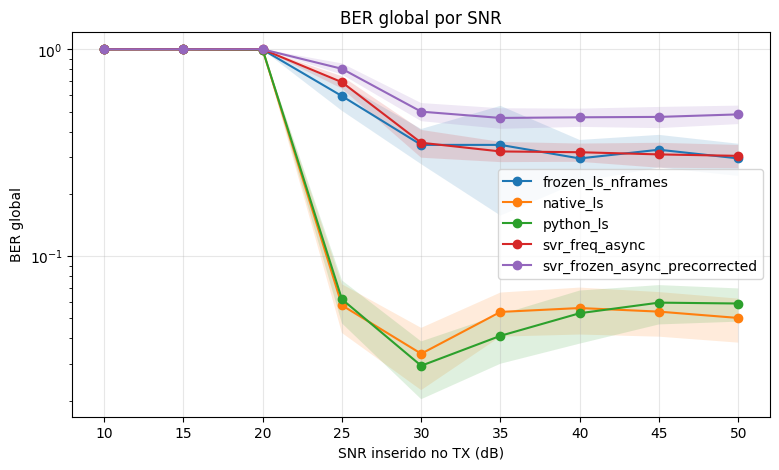

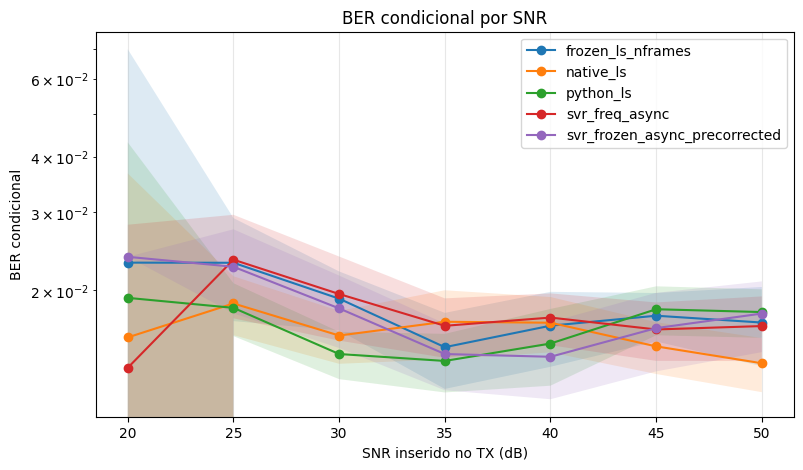

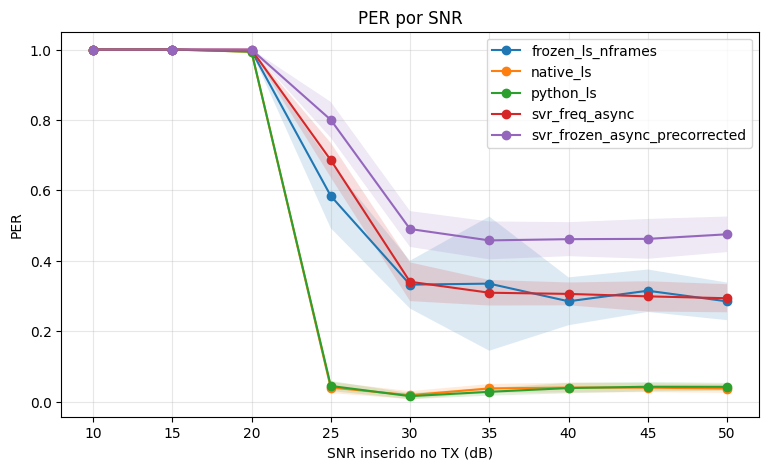

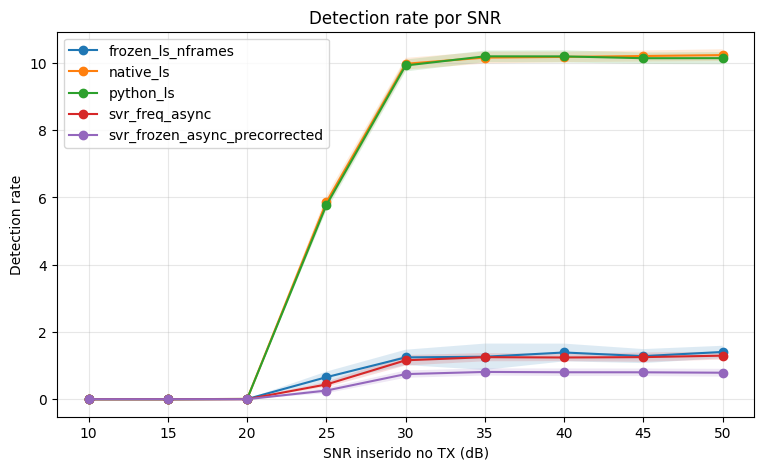

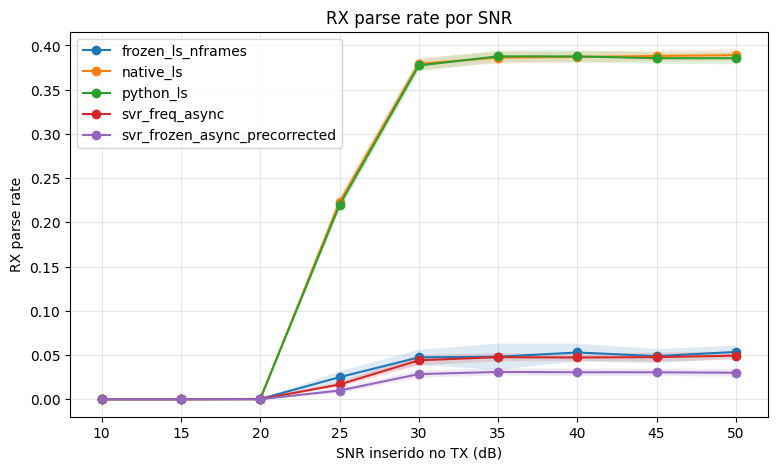

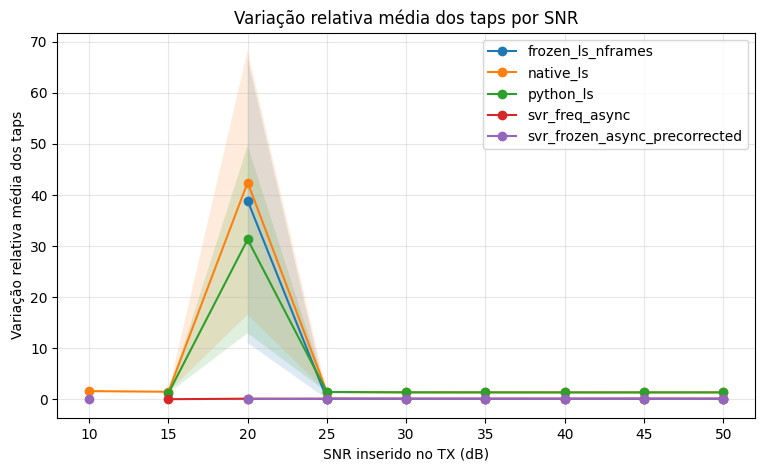

In [ ]:
def plot_metric_vs_snr(df: pd.DataFrame, metric: str, ylabel: str, yscale: str = "linear"):
    if df.empty or metric not in df.columns:
        print(f"Sem dados para {metric}")
        return
    fig, ax = plt.subplots(figsize=(9, 5))
    for estimator, g in df.groupby("estimator"):
        stats = g.groupby("snrdb")[metric].agg(["mean", "std", "count"]).reset_index().sort_values("snrdb")
        stats["std"] = stats["std"].fillna(0.0)
        ax.plot(stats["snrdb"], stats["mean"], marker="o", label=estimator)
        if stats["count"].max() > 1:
            ax.fill_between(stats["snrdb"], stats["mean"] - stats["std"], stats["mean"] + stats["std"], alpha=0.15)
    ax.set_title(f"{ylabel} por SNR")
    ax.set_xlabel("SNR inserido no TX (dB)")
    ax.set_ylabel(ylabel)
    if yscale == "log":
        ax.set_yscale("log")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="best")
    plt.show()

for metric, label, scale in available_metrics:
    plot_metric_vs_snr(plot_df, metric, label, scale)


## 9. Ranking visual por estimador

Aqui o foco é destacar diferenças grandes, não listar tudo. As barras resumem o desempenho médio global de cada estimador no benchmark carregado.


,estimator,ber_conditional,per,detection_rate,tap_delta_rel_mean,elapsed_wall_s
4,svr_frozen_async_precorrected,0.013071,0.9849,0.0162,0.034337,5.052646
0,frozen_ls_nframes,0.016295,0.5862,0.7805,9.043912,5.041391
3,svr_freq_async,0.016982,0.8701,0.1547,0.094633,5.021520
1,native_ls,0.018768,0.4201,6.0721,11.269617,5.017777
2,python_ls,0.029258,0.4204,6.0702,5.170644,5.015972


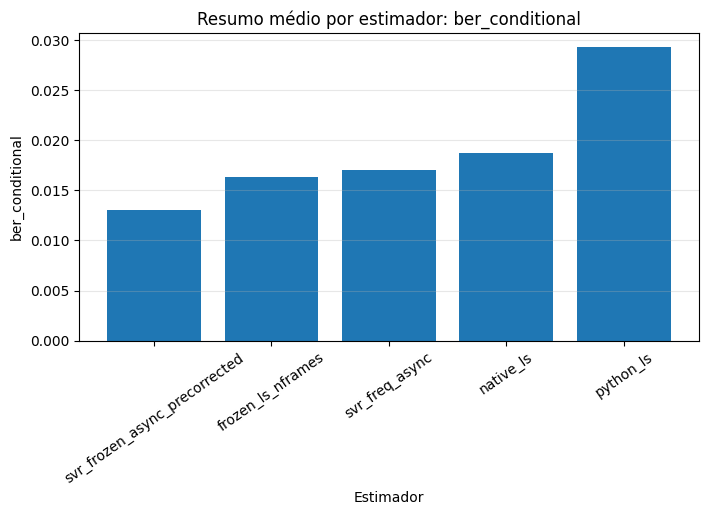

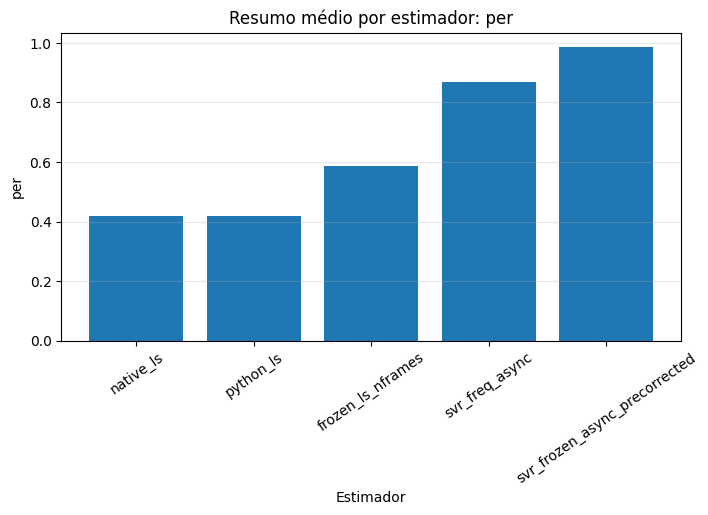

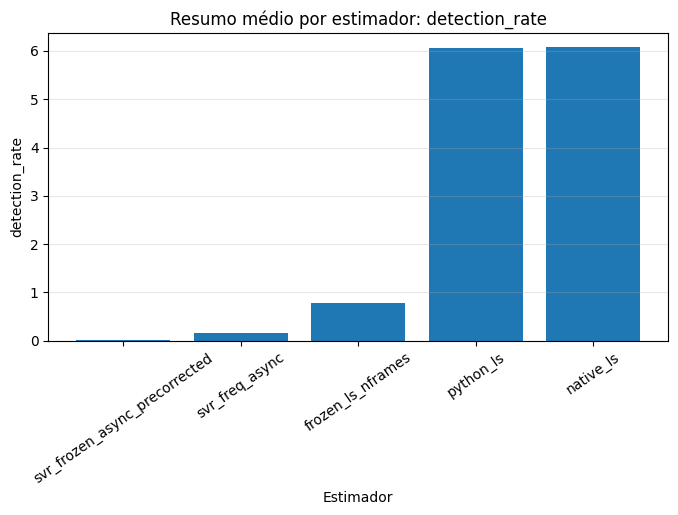

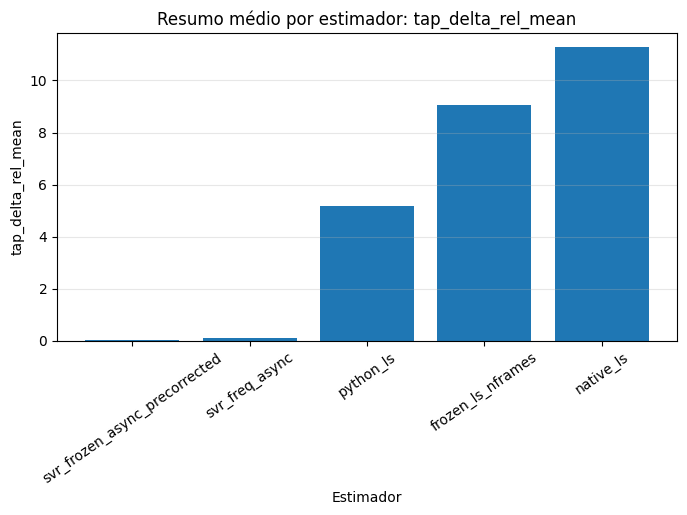

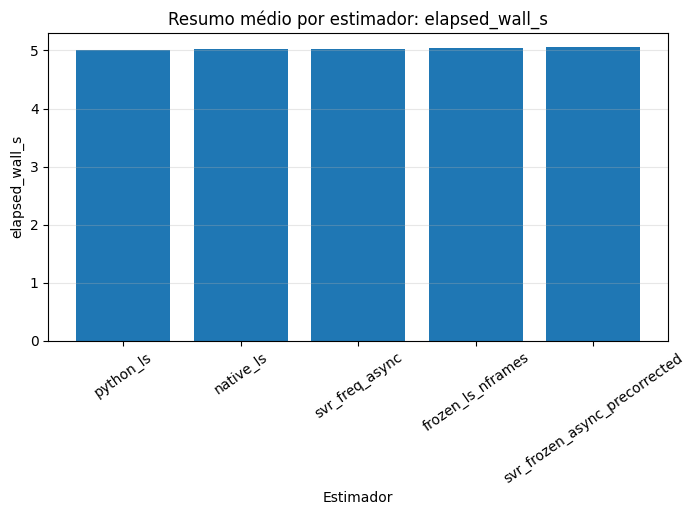

In [ ]:
def plot_estimator_summary(df: pd.DataFrame):
    if df.empty:
        print("Sem dados.")
        return
    summary_cols = [c for c in ["ber_conditional", "per", "detection_rate", "tap_delta_rel_mean", "elapsed_wall_s"] if c in df.columns]
    if not summary_cols:
        print("Sem métricas de resumo disponíveis.")
        return
    summary = df.groupby("estimator")[summary_cols].mean(numeric_only=True).reset_index()
    display(summary.sort_values(summary_cols[0] if summary_cols else "estimator"))
    for col in summary_cols:
        fig, ax = plt.subplots(figsize=(8, 4))
        ordered = summary.sort_values(col)
        ax.bar(ordered["estimator"], ordered[col])
        ax.set_title(f"Resumo médio por estimador: {col}")
        ax.set_xlabel("Estimador")
        ax.set_ylabel(col)
        ax.tick_params(axis="x", rotation=35)
        ax.grid(True, axis="y", alpha=0.3)
        plt.show()

plot_estimator_summary(plot_df)


## 10. Robustez entre repetições

Estes boxplots ajudam a ver se um estimador é estável ou se só funciona bem em algumas execuções.


/tmp/ipykernel_37890/126699161.py:16: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=labels, showmeans=True)


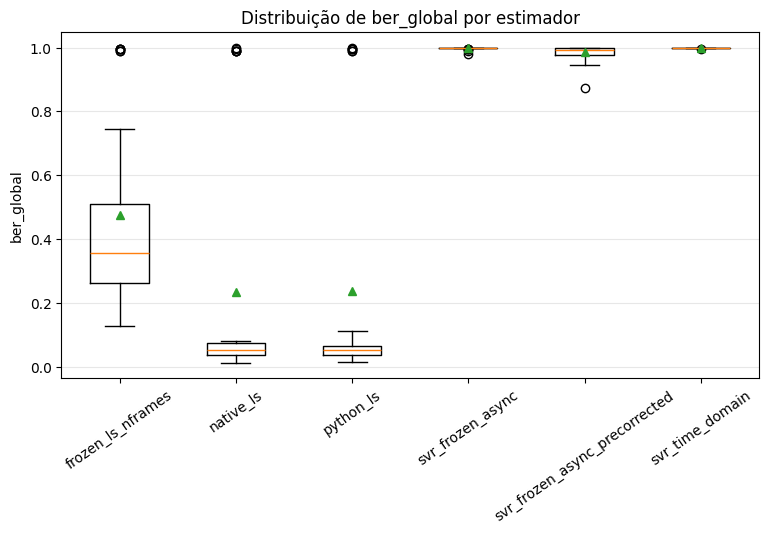

/tmp/ipykernel_37890/126699161.py:16: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=labels, showmeans=True)


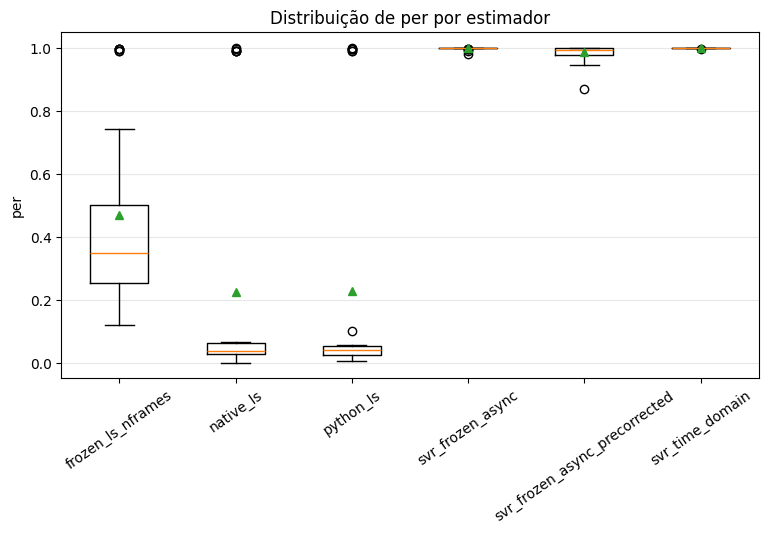

/tmp/ipykernel_37890/126699161.py:16: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=labels, showmeans=True)


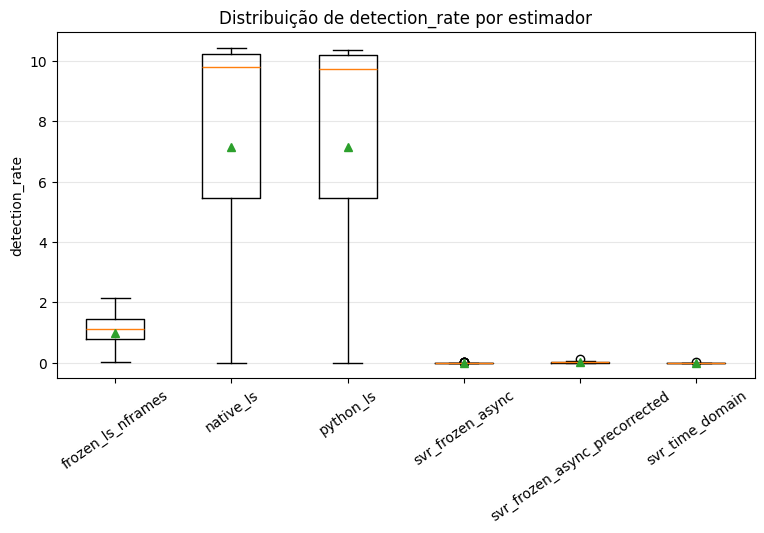

/tmp/ipykernel_37890/126699161.py:16: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=labels, showmeans=True)


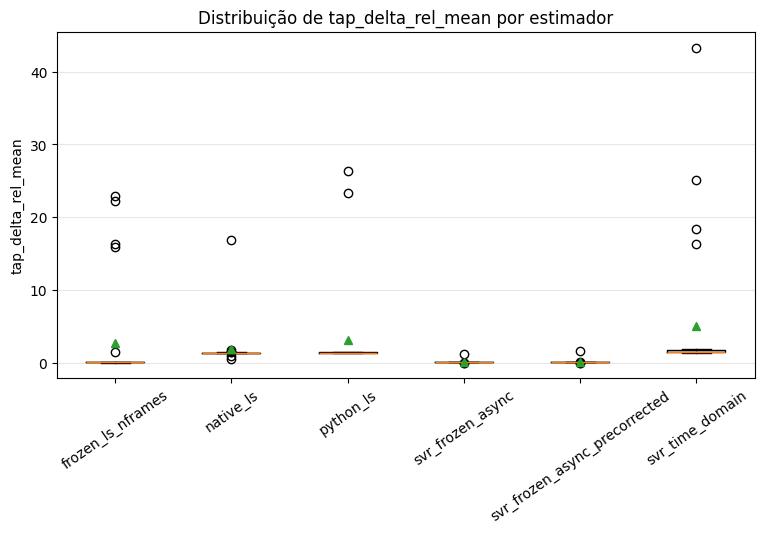

In [ ]:
def boxplot_by_estimator(df: pd.DataFrame, metric: str):
    if df.empty or metric not in df.columns:
        print(f"Sem dados para {metric}")
        return
    data = []
    labels = []
    for est, g in df.groupby("estimator"):
        vals = g[metric].dropna().values
        if len(vals):
            data.append(vals)
            labels.append(est)
    if not data:
        print(f"Sem valores numéricos para {metric}")
        return
    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.boxplot(data, labels=labels, showmeans=True)
    ax.set_title(f"Distribuição de {metric} por estimador")
    ax.set_ylabel(metric)
    ax.tick_params(axis="x", rotation=35)
    ax.grid(True, axis="y", alpha=0.3)
    plt.show()

for metric in ["ber_global", "per", "detection_rate", "tap_delta_rel_mean"]:
    if metric in plot_df.columns:
        boxplot_by_estimator(plot_df, metric)


## 11. Exploração temporal do canal pelos taps

Quando `--record_channel_taps` está ativo, cada run salva um `channel_taps.npz` com:

- `chan_taps`: matriz `frames × FFT length`, complexa;
- `carr_offset`: offset de portadora por frame.

Os gráficos abaixo exploram potência por frame, variação relativa frame-a-frame, offset de portadora e um mapa tempo × subportadora.


In [ ]:
def load_taps_npz(path: str | Path) -> dict[str, np.ndarray] | None:
    path = Path(path)
    if not path.exists():
        return None
    try:
        z = np.load(path)
        return {k: z[k] for k in z.files}
    except Exception as exc:
        print("Falha lendo", path, exc)
        return None


def channel_time_features(chan_taps: np.ndarray) -> pd.DataFrame:
    h = np.asarray(chan_taps)
    if h.ndim != 2 or h.shape[0] == 0:
        return pd.DataFrame()
    power = np.sum(np.abs(h) ** 2, axis=1)
    mean_abs = np.mean(np.abs(h), axis=1)
    max_abs = np.max(np.abs(h), axis=1)
    if h.shape[0] >= 2:
        delta = np.linalg.norm(h[1:] - h[:-1], axis=1)
        prev = np.linalg.norm(h[:-1], axis=1)
        rel_delta = delta / np.maximum(prev, 1e-12)
        rel_delta = np.r_[np.nan, rel_delta]
        delta = np.r_[np.nan, delta]
    else:
        delta = np.full(h.shape[0], np.nan)
        rel_delta = np.full(h.shape[0], np.nan)
    return pd.DataFrame({
        "frame": np.arange(h.shape[0]),
        "tap_power": power,
        "tap_mean_abs": mean_abs,
        "tap_max_abs": max_abs,
        "tap_delta_norm": delta,
        "tap_delta_rel": rel_delta,
    })


def pick_representative_runs(df: pd.DataFrame, estimators: list[str] | None = None, snrdb: float | None = None) -> pd.DataFrame:
    if df.empty:
        return df
    q = df.copy()
    if estimators is not None:
        q = q[q["estimator"].isin(estimators)]
    if snrdb is not None and "snrdb" in q.columns:
        q = q[np.isclose(q["snrdb"], snrdb)]
    # Prefer primeira repetição disponível para cada estimador.
    q = q.sort_values(["estimator", "repetition"])
    return q.groupby("estimator", as_index=False).head(1)

# Ajuste aqui para olhar um SNR específico. None usa o primeiro disponível.
CHANNEL_SNR_TO_INSPECT = None
if not plot_df.empty and CHANNEL_SNR_TO_INSPECT is None and "snrdb" in plot_df.columns:
    CHANNEL_SNR_TO_INSPECT = sorted(plot_df["snrdb"].dropna().unique())[0]

rep_runs = pick_representative_runs(plot_df, snrdb=CHANNEL_SNR_TO_INSPECT)
print("SNR inspecionado:", CHANNEL_SNR_TO_INSPECT)
rep_runs[[c for c in ["estimator", "snrdb", "repetition", "taps_path", "recorded_frames"] if c in rep_runs.columns]]


SNR inspecionado: 20.0


,estimator,snrdb,repetition,taps_path,recorded_frames
60,frozen_ls_nframes,20.0,1,/home/pesquisa/HEst_Prototyping/ofdm_modulariz...,4
0,native_ls,20.0,1,/home/pesquisa/HEst_Prototyping/ofdm_modulariz...,2
30,python_ls,20.0,1,/home/pesquisa/HEst_Prototyping/ofdm_modulariz...,1
120,svr_frozen_async,20.0,1,/home/pesquisa/HEst_Prototyping/ofdm_modulariz...,1
150,svr_frozen_async_precorrected,20.0,1,/home/pesquisa/HEst_Prototyping/ofdm_modulariz...,1
90,svr_time_domain,20.0,1,/home/pesquisa/HEst_Prototyping/ofdm_modulariz...,0


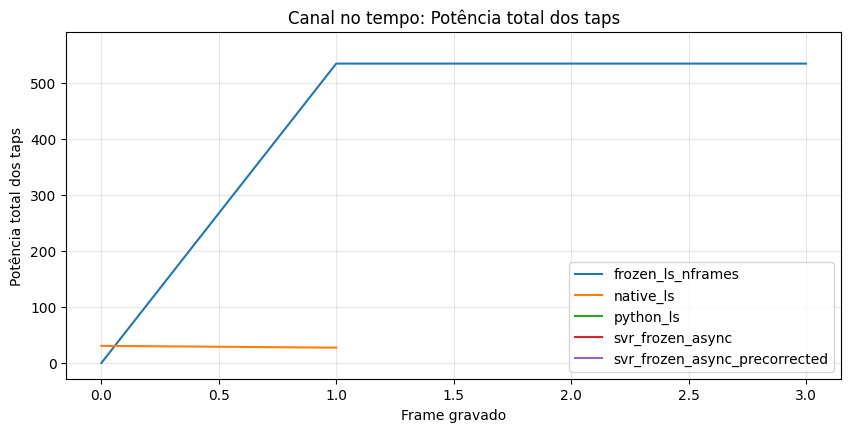

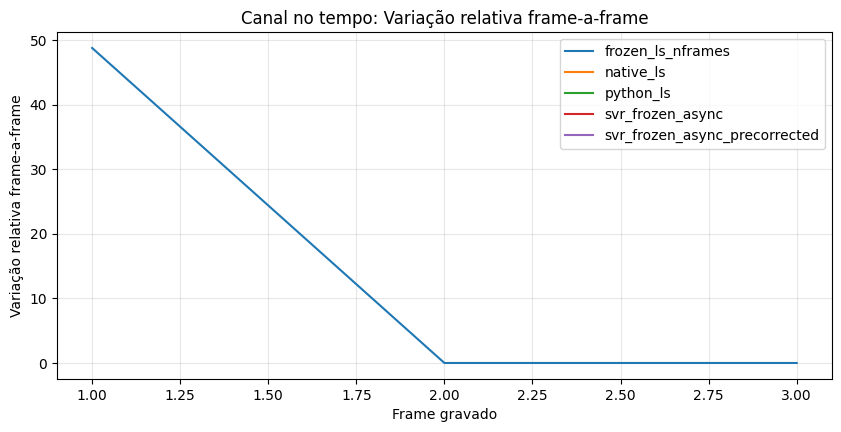

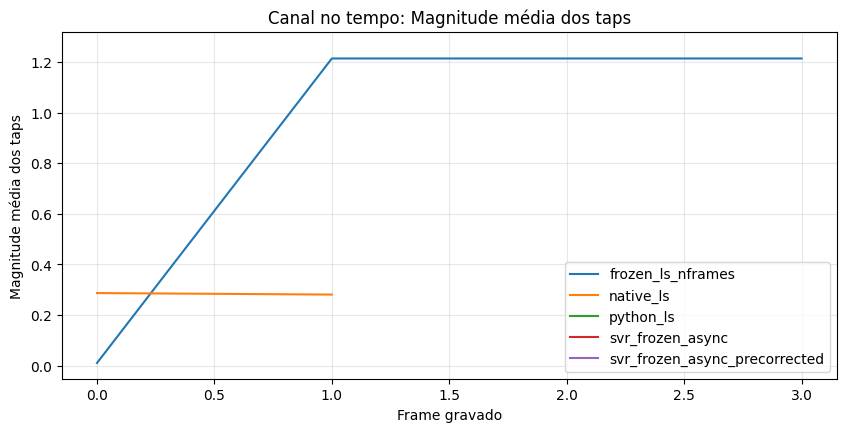

In [ ]:
def plot_channel_time_series(rep_runs: pd.DataFrame):
    if rep_runs.empty:
        print("Sem runs representativos.")
        return
    features = []
    for _, row in rep_runs.iterrows():
        taps = load_taps_npz(row.get("taps_path", ""))
        if not taps or "chan_taps" not in taps:
            continue
        f = channel_time_features(taps["chan_taps"])
        if f.empty:
            continue
        f["estimator"] = row["estimator"]
        f["snrdb"] = row.get("snrdb", np.nan)
        features.append(f)
    if not features:
        print("Nenhum channel_taps.npz válido encontrado.")
        return
    feat = pd.concat(features, ignore_index=True)
    for metric, ylabel in [
        ("tap_power", "Potência total dos taps"),
        ("tap_delta_rel", "Variação relativa frame-a-frame"),
        ("tap_mean_abs", "Magnitude média dos taps"),
    ]:
        fig, ax = plt.subplots(figsize=(10, 4.5))
        for estimator, g in feat.groupby("estimator"):
            ax.plot(g["frame"], g[metric], label=estimator)
        ax.set_title(f"Canal no tempo: {ylabel}")
        ax.set_xlabel("Frame gravado")
        ax.set_ylabel(ylabel)
        ax.grid(True, alpha=0.3)
        ax.legend(loc="best")
        plt.show()
    return feat

channel_feat_df = plot_channel_time_series(rep_runs)


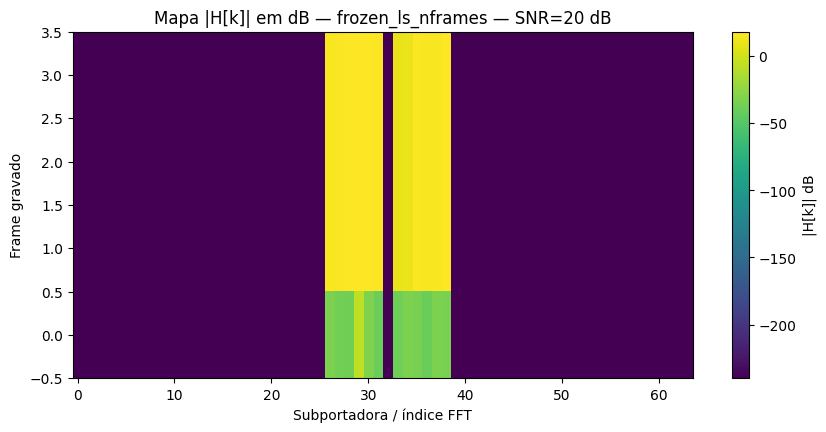

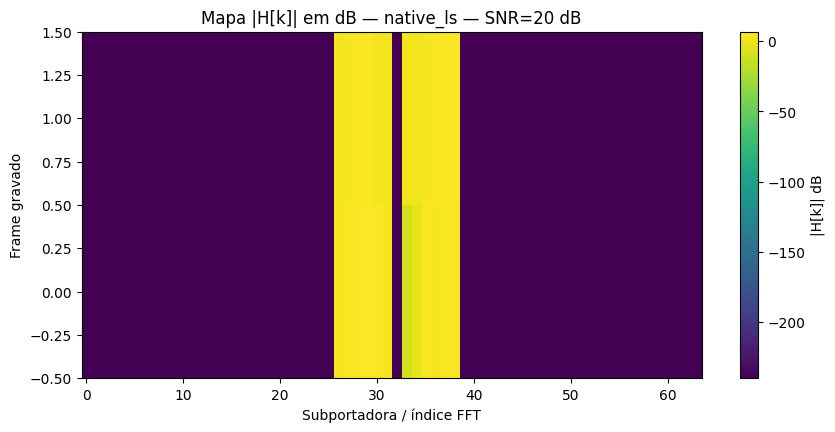

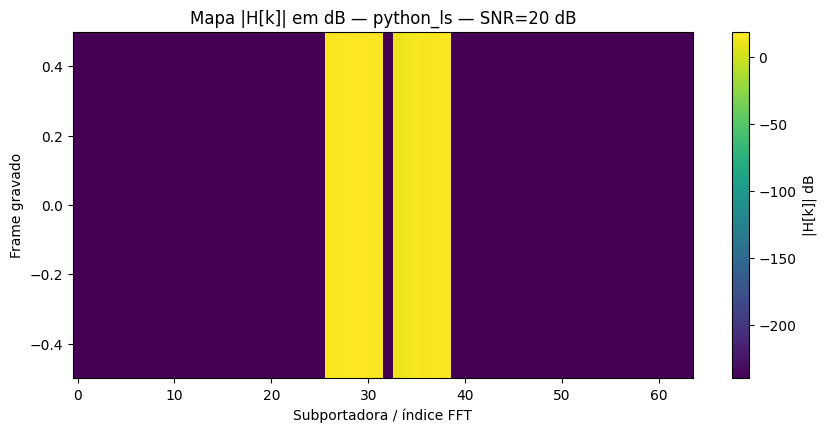

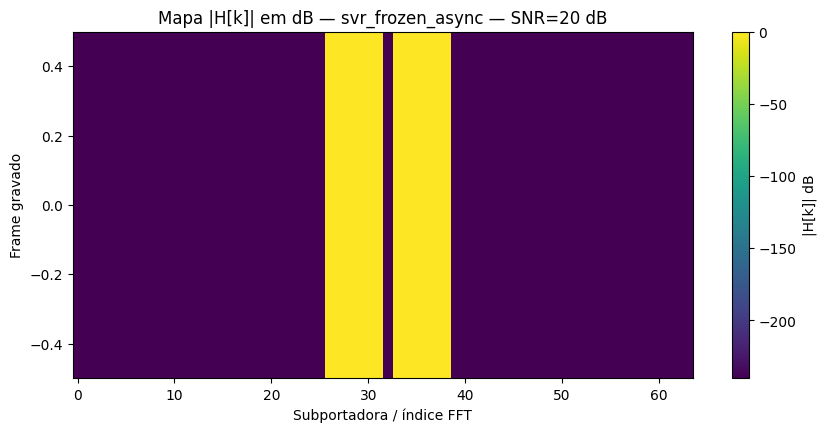

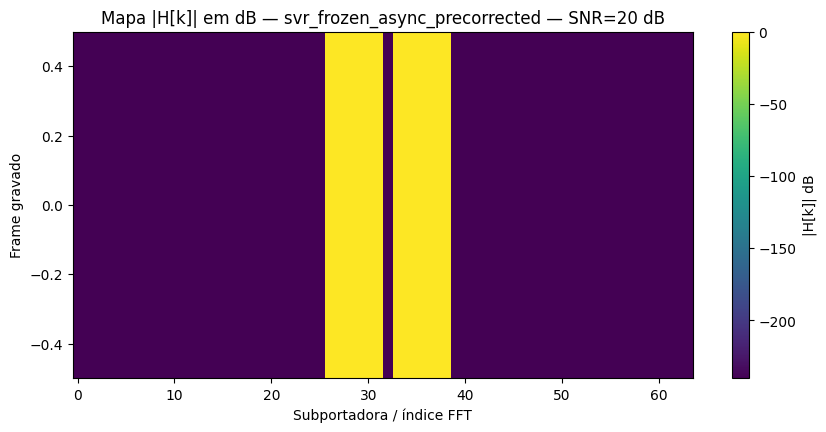

In [ ]:
def plot_channel_heatmaps(rep_runs: pd.DataFrame, max_estimators: int = 6):
    if rep_runs.empty:
        print("Sem runs representativos.")
        return
    shown = 0
    for _, row in rep_runs.iterrows():
        if shown >= max_estimators:
            break
        taps = load_taps_npz(row.get("taps_path", ""))
        if not taps or "chan_taps" not in taps:
            continue
        h = np.asarray(taps["chan_taps"])
        if h.ndim != 2 or h.shape[0] == 0:
            continue
        mag_db = 20 * np.log10(np.abs(h) + 1e-12)
        fig, ax = plt.subplots(figsize=(10, 4.5))
        im = ax.imshow(mag_db, aspect="auto", origin="lower")
        ax.set_title(f"Mapa |H[k]| em dB — {row['estimator']} — SNR={row.get('snrdb', np.nan):g} dB")
        ax.set_xlabel("Subportadora / índice FFT")
        ax.set_ylabel("Frame gravado")
        plt.colorbar(im, ax=ax, label="|H[k]| dB")
        plt.show()
        shown += 1

plot_channel_heatmaps(rep_runs)


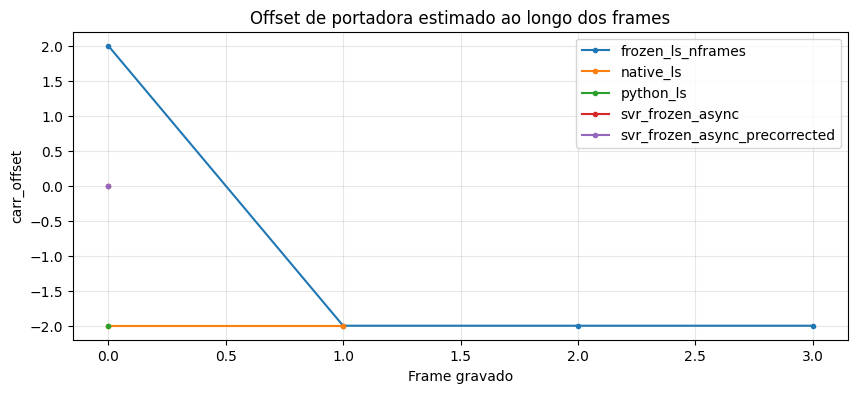

In [ ]:
def plot_carr_offset(rep_runs: pd.DataFrame):
    if rep_runs.empty:
        print("Sem runs representativos.")
        return
    any_plot = False
    fig, ax = plt.subplots(figsize=(10, 4))
    for _, row in rep_runs.iterrows():
        taps = load_taps_npz(row.get("taps_path", ""))
        if not taps or "carr_offset" not in taps:
            continue
        c = np.asarray(taps["carr_offset"])
        if c.size == 0:
            continue
        ax.plot(np.arange(c.size), c, marker=".", linestyle="-", label=row["estimator"])
        any_plot = True
    if not any_plot:
        plt.close(fig)
        print("Nenhum carr_offset encontrado.")
        return
    ax.set_title("Offset de portadora estimado ao longo dos frames")
    ax.set_xlabel("Frame gravado")
    ax.set_ylabel("carr_offset")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="best")
    plt.show()

plot_carr_offset(rep_runs)


## 12. Relações entre métricas

Esses gráficos tentam responder perguntas como:

- maior variação dos taps coincide com pior BER/PER?
- detection rate alto sempre implica BER baixo?
- algum estimador é mais lento ou instável?


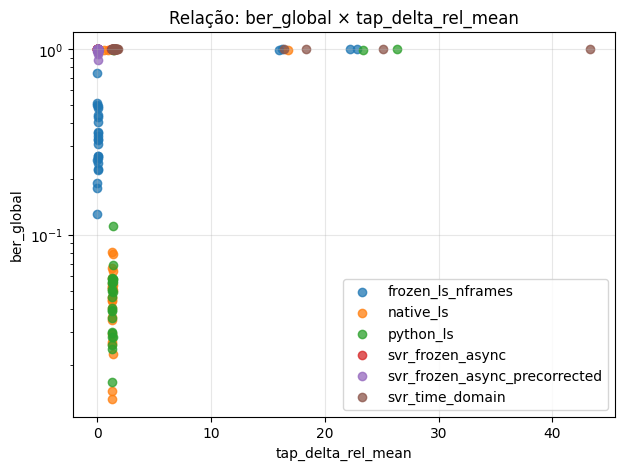

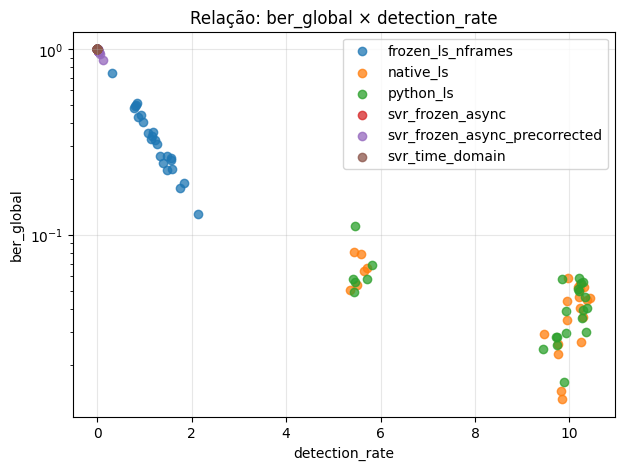

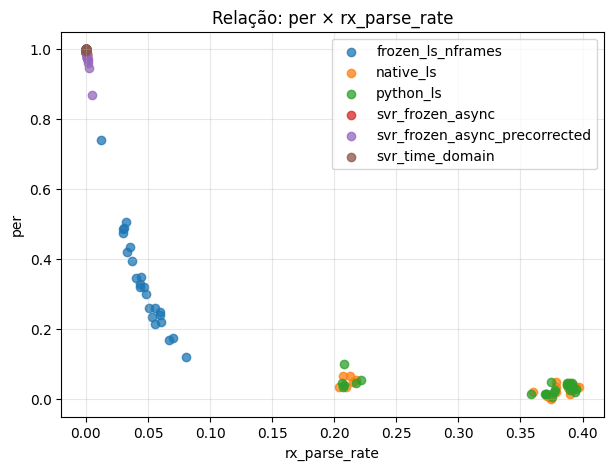

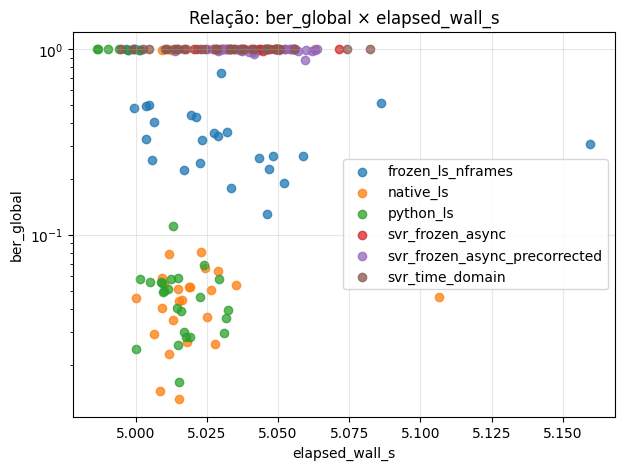

In [ ]:
def scatter_metric_relation(df: pd.DataFrame, x: str, y: str):
    if df.empty or x not in df.columns or y not in df.columns:
        print(f"Sem dados para {x} × {y}")
        return
    fig, ax = plt.subplots(figsize=(7, 5))
    for estimator, g in df.groupby("estimator"):
        ax.scatter(g[x], g[y], label=estimator, alpha=0.75)
    ax.set_title(f"Relação: {y} × {x}")
    ax.set_xlabel(x)
    ax.set_ylabel(y)
    if y.startswith("ber"):
        ax.set_yscale("log")
    if x.startswith("ber"):
        ax.set_xscale("log")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="best")
    plt.show()

for x, y in [
    ("tap_delta_rel_mean", "ber_global"),
    ("detection_rate", "ber_global"),
    ("rx_parse_rate", "per"),
    ("elapsed_wall_s", "ber_global"),
]:
    scatter_metric_relation(plot_df, x, y)


## 13. Tabelas mínimas: destaques expressivos

As tabelas abaixo são propositalmente curtas. Elas destacam melhores/piores casos, falhas e casos em que um estimador parece se afastar muito da baseline.


In [ ]:
def show_highlights(df: pd.DataFrame):
    if df.empty:
        print("Sem dados.")
        return
    cols = [c for c in ["estimator", "snrdb", "repetition", "returncode", "ber_global", "per", "detection_rate", "rx_parse_rate", "matched_packets", "missing_packets", "tap_delta_rel_mean", "elapsed_wall_s"] if c in df.columns]
    q = df[cols].copy()

    print("Falhas de execução ou retorno não-zero:")
    fail = q[q.get("returncode", 0) != 0] if "returncode" in q.columns else pd.DataFrame()
    display(fail.head(20) if len(fail) else pd.DataFrame({"status": ["nenhuma falha de returncode encontrada"]}))

    if "ber_global" in q.columns:
        print("Melhores BER globais:")
        display(q.sort_values("ber_global", na_position="last").head(10))
        print("Piores BER globais:")
        display(q.sort_values("ber_global", ascending=False, na_position="last").head(10))

    if "per" in q.columns:
        print("Piores PER:")
        display(q.sort_values("per", ascending=False, na_position="last").head(10))

    if "tap_delta_rel_mean" in q.columns:
        print("Maiores variações relativas médias do canal:")
        display(q.sort_values("tap_delta_rel_mean", ascending=False, na_position="last").head(10))

show_highlights(plot_df)


Falhas de execução ou retorno não-zero:


,status
0,nenhuma falha de returncode encontrada


Melhores BER globais:


,estimator,snrdb,repetition,returncode,ber_global,per,detection_rate,rx_parse_rate,matched_packets,missing_packets,tap_delta_rel_mean,elapsed_wall_s
15,native_ls,30.0,4,0,0.013051,0.000,9.840,0.374216,200,0,1.321839,5.015076
16,native_ls,30.0,5,0,0.014420,0.005,9.815,0.373265,199,1,1.328398,5.008425
45,python_ls,30.0,4,0,0.016057,0.005,9.875,0.375547,199,1,1.309286,5.015076
17,native_ls,30.0,6,0,0.022961,0.010,9.760,0.371173,198,2,1.339336,5.011794
44,python_ls,30.0,3,0,0.024345,0.015,9.430,0.358623,197,3,1.328030,5.000122
46,python_ls,30.0,5,0,0.025655,0.015,9.740,0.370413,197,3,1.325415,5.014803
13,native_ls,30.0,2,0,0.025908,0.015,9.760,0.371173,197,3,1.280482,5.027868
29,native_ls,50.0,6,0,0.026592,0.015,10.245,0.389618,197,3,1.303213,5.017947
43,python_ls,30.0,2,0,0.028259,0.015,9.745,0.370603,197,3,1.326720,5.019004
47,python_ls,30.0,6,0,0.028318,0.015,9.725,0.369842,197,3,1.340162,5.017580


Piores BER globais:


,estimator,snrdb,repetition,returncode,ber_global,per,detection_rate,rx_parse_rate,matched_packets,missing_packets,tap_delta_rel_mean,elapsed_wall_s
3,native_ls,20.0,4,0,1.0,1.0,0.0,0.0,0,200,1.726215,5.063136
31,python_ls,20.0,2,0,1.0,1.0,0.0,0.0,0,200,NaN,4.986797
134,svr_frozen_async,30.0,3,0,1.0,1.0,0.0,0.0,0,200,0.028305,5.020463
132,svr_frozen_async,30.0,1,0,1.0,1.0,0.0,0.0,0,200,0.037444,5.049791
147,svr_frozen_async,50.0,4,0,1.0,1.0,0.0,0.0,0,200,0.026889,5.047280
141,svr_frozen_async,40.0,4,0,1.0,1.0,0.0,0.0,0,200,0.021994,5.052586
135,svr_frozen_async,30.0,4,0,1.0,1.0,0.0,0.0,0,200,0.031082,5.056143
136,svr_frozen_async,30.0,5,0,1.0,1.0,0.0,0.0,0,200,0.030300,5.029995
138,svr_frozen_async,40.0,1,0,1.0,1.0,0.0,0.0,0,200,0.023914,5.049895
137,svr_frozen_async,30.0,6,0,1.0,1.0,0.0,0.0,0,200,0.027015,5.023125


Piores PER:


,estimator,snrdb,repetition,returncode,ber_global,per,detection_rate,rx_parse_rate,matched_packets,missing_packets,tap_delta_rel_mean,elapsed_wall_s
3,native_ls,20.0,4,0,1.0,1.0,0.0,0.0,0,200,1.726215,5.063136
31,python_ls,20.0,2,0,1.0,1.0,0.0,0.0,0,200,NaN,4.986797
134,svr_frozen_async,30.0,3,0,1.0,1.0,0.0,0.0,0,200,0.028305,5.020463
132,svr_frozen_async,30.0,1,0,1.0,1.0,0.0,0.0,0,200,0.037444,5.049791
147,svr_frozen_async,50.0,4,0,1.0,1.0,0.0,0.0,0,200,0.026889,5.047280
141,svr_frozen_async,40.0,4,0,1.0,1.0,0.0,0.0,0,200,0.021994,5.052586
135,svr_frozen_async,30.0,4,0,1.0,1.0,0.0,0.0,0,200,0.031082,5.056143
136,svr_frozen_async,30.0,5,0,1.0,1.0,0.0,0.0,0,200,0.030300,5.029995
138,svr_frozen_async,40.0,1,0,1.0,1.0,0.0,0.0,0,200,0.023914,5.049895
137,svr_frozen_async,30.0,6,0,1.0,1.0,0.0,0.0,0,200,0.027015,5.023125


Maiores variações relativas médias do canal:


,estimator,snrdb,repetition,returncode,ber_global,per,detection_rate,rx_parse_rate,matched_packets,missing_packets,tap_delta_rel_mean,elapsed_wall_s
93,svr_time_domain,20.0,4,0,1.000000,1.000,0.000,0.00000,0,200,43.336662,5.004554
32,python_ls,20.0,3,0,0.995417,0.995,0.005,0.00019,1,199,26.301979,4.990418
92,svr_time_domain,20.0,3,0,1.000000,1.000,0.000,0.00000,0,200,25.142965,4.999226
35,python_ls,20.0,6,0,0.990089,0.990,0.010,0.00038,2,198,23.360264,5.001118
63,frozen_ls_nframes,20.0,4,0,0.995417,0.995,0.005,0.00019,1,199,22.858269,4.996559
64,frozen_ls_nframes,20.0,5,0,0.995000,0.995,0.005,0.00019,1,199,22.236874,4.999499
95,svr_time_domain,20.0,6,0,1.000000,1.000,0.000,0.00000,0,200,18.307898,5.010153
5,native_ls,20.0,6,0,0.990089,0.990,0.015,0.00057,2,198,16.800560,5.009169
91,svr_time_domain,20.0,2,0,1.000000,1.000,0.000,0.00000,0,200,16.372730,5.021571
60,frozen_ls_nframes,20.0,1,0,0.995238,0.995,0.005,0.00019,1,199,16.260651,4.999611


## 14. Comparação contra baseline

Esta seção calcula deltas relativos contra `native_ls` no mesmo SNR e repetição. É útil para separar melhoria real de variação normal da transmissão.


,estimator,snrdb,repetition,delta_ber_global,ratio_ber_global,delta_ber_conditional,ratio_ber_conditional,delta_per,ratio_per,delta_detection_rate,ratio_detection_rate,delta_rx_parse_rate,ratio_rx_parse_rate,delta_tap_delta_rel_mean,ratio_tap_delta_rel_mean
0,native_ls,20.0,1,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0
1,native_ls,20.0,2,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0
2,native_ls,20.0,3,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0
3,native_ls,20.0,4,0.0,1.0,NaN,NaN,0.0,1.0,0.0,NaN,0.0,NaN,0.0,1.0
4,native_ls,20.0,5,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,NaN,NaN
5,native_ls,20.0,6,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0
6,native_ls,25.0,1,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0
7,native_ls,25.0,2,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0
8,native_ls,25.0,3,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0
9,native_ls,25.0,4,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0


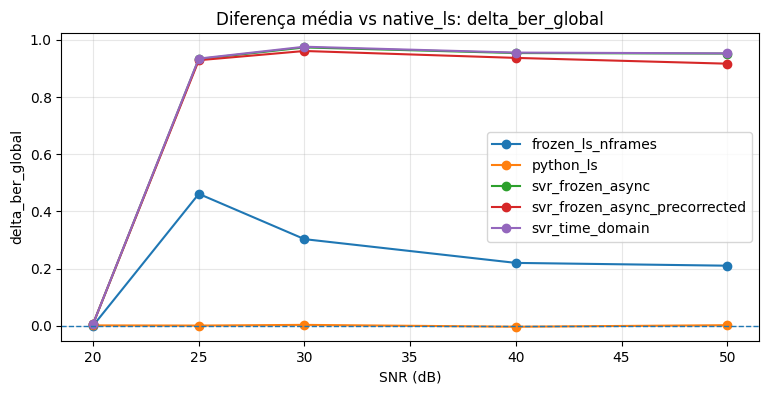

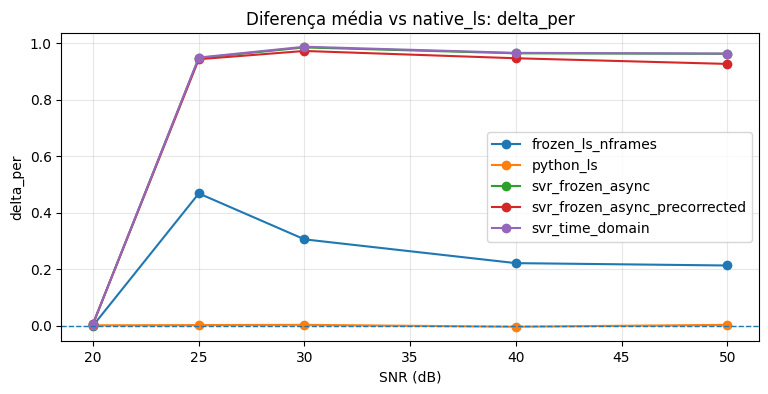

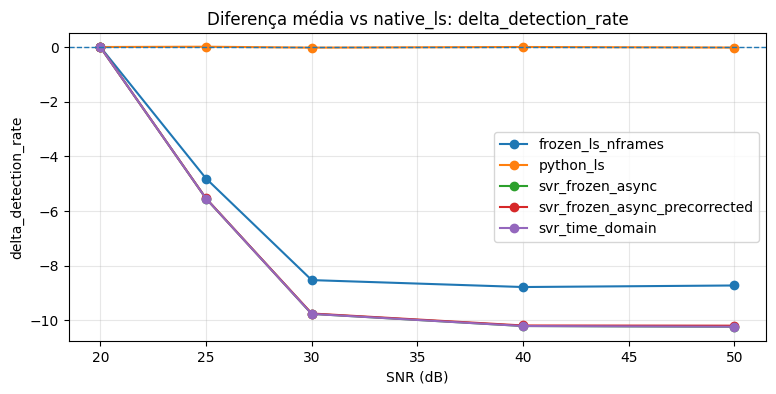

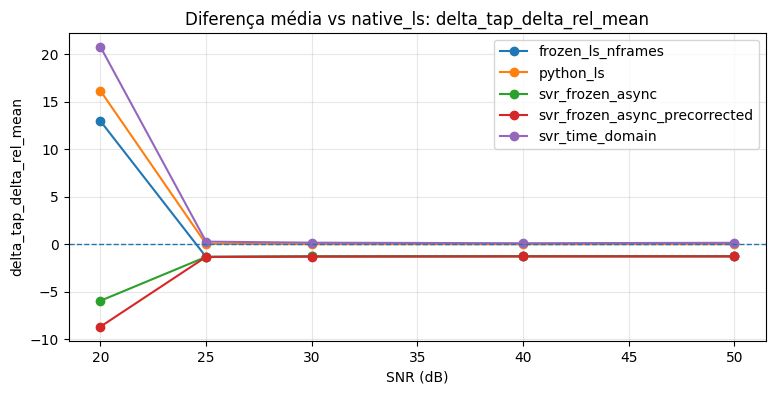

In [ ]:
def compare_to_baseline(df: pd.DataFrame, baseline: str = "native_ls") -> pd.DataFrame:
    if df.empty or "estimator" not in df.columns:
        return pd.DataFrame()
    keys = ["snrdb", "repetition"]
    metrics = [c for c in ["ber_global", "ber_conditional", "per", "detection_rate", "rx_parse_rate", "tap_delta_rel_mean"] if c in df.columns]
    base = df[df["estimator"] == baseline][keys + metrics].copy()
    if base.empty:
        print("Baseline não encontrada:", baseline)
        return pd.DataFrame()
    base = base.rename(columns={m: f"{m}_baseline" for m in metrics})
    merged = df.merge(base, on=keys, how="left")
    for m in metrics:
        b = f"{m}_baseline"
        merged[f"delta_{m}"] = merged[m] - merged[b]
        merged[f"ratio_{m}"] = merged[m] / merged[b].replace(0, np.nan)
    return merged

cmp_df = compare_to_baseline(plot_df, baseline="native_ls")

if not cmp_df.empty:
    delta_cols = [c for c in cmp_df.columns if c.startswith("delta_") or c.startswith("ratio_")]
    show_cols = ["estimator", "snrdb", "repetition"] + delta_cols
    display(cmp_df[show_cols].head(20))

    for metric in ["delta_ber_global", "delta_per", "delta_detection_rate", "delta_tap_delta_rel_mean"]:
        if metric in cmp_df.columns:
            fig, ax = plt.subplots(figsize=(9, 4))
            for est, g in cmp_df[cmp_df["estimator"] != "native_ls"].groupby("estimator"):
                stats = g.groupby("snrdb")[metric].mean().reset_index().sort_values("snrdb")
                ax.plot(stats["snrdb"], stats[metric], marker="o", label=est)
            ax.axhline(0, linestyle="--", linewidth=1)
            ax.set_title(f"Diferença média vs native_ls: {metric}")
            ax.set_xlabel("SNR (dB)")
            ax.set_ylabel(metric)
            ax.grid(True, alpha=0.3)
            ax.legend(loc="best")
            plt.show()


## 15. Salvar figuras e resumo

A célula abaixo salva CSVs finais. Para salvar figuras automaticamente, é melhor transformar os blocos de plot em funções com `fig.savefig(...)`; os gráficos acima ficam interativos no notebook para exploração manual.


In [ ]:
if not plot_df.empty and LOAD_EXPERIMENT_DIR is not None:
    out_dir = Path(LOAD_EXPERIMENT_DIR)
    plot_df.to_csv(out_dir / "benchmark_prepared.csv", index=False)
    if 'cmp_df' in globals() and not cmp_df.empty:
        cmp_df.to_csv(out_dir / "benchmark_vs_native_ls.csv", index=False)
    print("Arquivos salvos em:", out_dir)
else:
    print("Sem resultados preparados para salvar.")


Arquivos salvos em: /home/pesquisa/HEst_Prototyping/ofdm_modularizer/ofdm_split/benchmark_visual_runs/benchmark_20260423_231232
